<a href="https://colab.research.google.com/github/jagtappranav2721-cpu/ML-Internship-FlyRank/blob/main/work/notebooks/w07_action_playbook.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# ML-10 — Content Action Playbook

This skeleton is yours to fill. Work the sections **in order** — each one has a one-line hint. Simple words, honest numbers.

> Working with an AI assistant? Tell it to read `skills/README.md` first and load the one skill this assignment names on its card.

Loading the dataset through Hugging Face

In [79]:
!pip -q install datasets huggingface_hub

In [80]:
from huggingface_hub import login, whoami

In [81]:
from huggingface_hub import login, whoami

login()
user = whoami()

print(f"Connected to Hugging Face user: {user['name']}")

Connected to Hugging Face user: LEOd2705


In [82]:
from datasets import get_dataset_config_names

configs = get_dataset_config_names("FlyRank/internship-warehouse")

print("Available configs:")
print(configs)

Available configs:
['dim_clients', 'dim_content', 'fact_content_daily_performance', 'fact_content_query_90d']


In [83]:
from datasets import get_dataset_config_names, load_dataset

dim_content = load_dataset(
    "FlyRank/internship-warehouse",
    name="dim_content",
    split="train"
)

print(f"\ndim_content rows: {len(dim_content):,}")
print(f"dim_content columns: {len(dim_content.column_names)}")

# 4. Show column names
print("\nColumns:")
print(dim_content.column_names)

# 5. Show first 3 rows
print("\nFirst 3 rows:")
print(dim_content[:3])


dim_content rows: 519,606
dim_content columns: 26

Columns:
['client_hash_id', 'content_hash_id', 'keyword_hash_id', 'url_hash_id', 'keyword_char_count', 'keyword_token_count', 'url_char_count', 'content_created_date', 'content_updated_date', 'content_type', 'search_volume', 'competition', 'competition_level', 'cpc', 'main_intent', 'backlinks', 'category_count', 'keyword_created_date', 'provider_used', 'model_used', 'char_count', 'word_count', 'last_optimized_date', 'optimization_eligible_date', 'is_published', 'is_deleted']

First 3 rows:
{'client_hash_id': ['client_04660893ae39614a', 'client_04660893ae39614a', 'client_04660893ae39614a'], 'content_hash_id': ['content_004de9653278b5a4', 'content_00dc5efae381b2ab', 'content_01410f2556c327ac'], 'keyword_hash_id': ['keyword_e754999ab88dd9f2', 'keyword_4329d7aede8e208b', 'keyword_9b08047d3d2a0406'], 'url_hash_id': ['url_d6091f18cf628794', 'url_3a66d2f2e36823ca', 'url_809eda7a7e20b3b2'], 'keyword_char_count': [22, 31, 22], 'keyword_token_c

In [84]:
from datasets import load_dataset

fact_query = load_dataset(
    "FlyRank/internship-warehouse",
    name="fact_content_query_90d",
    split="train"
)

print(f"fact_content_query_90d rows: {len(fact_query):,}")
print(f"Columns: {fact_query.column_names}")
print("\nFirst 3 rows:")
print(fact_query[:3])

fact_content_query_90d rows: 2,414,248
Columns: ['client_hash_id', 'content_hash_id', 'query_hash_id', 'query_char_count', 'query_token_count', 'window_start', 'window_end', 'impressions_90d', 'clicks_90d', 'impressions_last30', 'clicks_last30', 'impressions_prev30', 'clicks_prev30', 'avg_position_90d', 'avg_position_last30', 'avg_position_prev30', 'content_total_impressions_90d', 'content_visible_query_count', 'rare_query_count', 'rare_impressions_share', 'anonymized_impressions_share']

First 3 rows:
{'client_hash_id': ['client_08a6a72ff48e62c0', 'client_08a6a72ff48e62c0', 'client_08a6a72ff48e62c0'], 'content_hash_id': ['content_447894f2faf0d2bc', 'content_447894f2faf0d2bc', 'content_447894f2faf0d2bc'], 'query_hash_id': ['query_58b1b001f839d699', 'query_922b8eca2a24cd34', 'query_9f0c36a6ae2a6a99'], 'query_char_count': [17, 34, 16], 'query_token_count': [3, 7, 2], 'window_start': [datetime.date(2026, 4, 2), datetime.date(2026, 4, 2), datetime.date(2026, 4, 2)], 'window_end': [datetime

In [85]:
import pandas as pd

query_df = fact_query.to_pandas()

print("Unique content pages:", query_df["content_hash_id"].nunique())
print("Unique clients:", query_df["client_hash_id"].nunique())
print("Rows:", len(query_df))

Unique content pages: 133852
Unique clients: 52
Rows: 2414248


In [86]:
content_query = (
    query_df
    .groupby(["client_hash_id", "content_hash_id"], as_index=False)
    .agg({
        "impressions_90d": "sum",
        "clicks_90d": "sum",
        "impressions_last30": "sum",
        "clicks_last30": "sum",
        "impressions_prev30": "sum",
        "clicks_prev30": "sum",
        "avg_position_90d": "mean",
        "avg_position_last30": "mean",
        "avg_position_prev30": "mean",
        "content_visible_query_count": "max",
        "rare_query_count": "max",
        "rare_impressions_share": "max",
        "anonymized_impressions_share": "max"
    })
)

print("Page-level rows:", len(content_query))
print("Columns:", content_query.columns.tolist())
print("\nFirst 3 rows:")
print(content_query.head(3))

Page-level rows: 133852
Columns: ['client_hash_id', 'content_hash_id', 'impressions_90d', 'clicks_90d', 'impressions_last30', 'clicks_last30', 'impressions_prev30', 'clicks_prev30', 'avg_position_90d', 'avg_position_last30', 'avg_position_prev30', 'content_visible_query_count', 'rare_query_count', 'rare_impressions_share', 'anonymized_impressions_share']

First 3 rows:
            client_hash_id           content_hash_id  impressions_90d  \
0  client_06d356715a8ff3b6  content_0058bd88fb1821f2               16   
1  client_06d356715a8ff3b6  content_0059a4d4195810c9              395   
2  client_06d356715a8ff3b6  content_005b6b7f7b8dda7f              151   

   clicks_90d  impressions_last30  clicks_last30  impressions_prev30  \
0           0                  16              0                   0   
1           0                 123              0                 139   
2           0                  38              0                  59   

   clicks_prev30  avg_position_90d  avg_positi

In [87]:
# Merge page-level performance with content metadata
action_df = content_query.merge(
    dim_content.to_pandas(),
    on=["client_hash_id", "content_hash_id"],
    how="left"
)

print("Action dataset shape:", action_df.shape)
print("\nMissing content metadata:")
print(action_df[["content_created_date", "content_updated_date", "word_count",
                 "search_volume", "is_published", "is_deleted"]].isna().sum())

Action dataset shape: (133852, 39)

Missing content metadata:
content_created_date        0
content_updated_date        0
word_count              33297
search_volume            2289
is_published                0
is_deleted                  0
dtype: int64


In [88]:
action_df["click_change_pct"] = (
    (action_df["clicks_last30"] - action_df["clicks_prev30"])
    / action_df["clicks_prev30"].replace(0, pd.NA)
)

action_df["is_declining_proxy"] = (
    action_df["click_change_pct"] <= -0.20
)

print("Declining pages:", action_df["is_declining_proxy"].sum())
print("Non-declining pages:", (~action_df["is_declining_proxy"]).sum())
print("Missing decline signal:", action_df["is_declining_proxy"].isna().sum())

Declining pages: 16738
Non-declining pages: 117114
Missing decline signal: 0


In [89]:
FEATURES = [
    "impressions_prev30",
    "clicks_prev30",
    "avg_position_prev30",
    "word_count",
    "search_volume",
    "keyword_char_count",
    "url_char_count"
]

print("Features:")
print(FEATURES)

print("\nMissing required columns:")
print([col for col in FEATURES if col not in action_df.columns])

Features:
['impressions_prev30', 'clicks_prev30', 'avg_position_prev30', 'word_count', 'search_volume', 'keyword_char_count', 'url_char_count']

Missing required columns:
[]


## 1. Ranked actions + reason codes

*The queue: what to do first, and why, in words a human trusts.*

In [90]:
from sklearn.model_selection import GroupShuffleSplit
from sklearn.ensemble import RandomForestClassifier

TARGET = "is_declining_proxy"

splitter = GroupShuffleSplit(
    n_splits=1,
    test_size=0.20,
    random_state=42
)

train_idx, test_idx = next(
    splitter.split(
        action_df,
        y=action_df[TARGET],
        groups=action_df["client_hash_id"]
    )
)

train_df = action_df.iloc[train_idx].copy()
test_df = action_df.iloc[test_idx].copy()

X_train = train_df[FEATURES].copy()
X_test = test_df[FEATURES].copy()

# Fill missing values using training medians
for col in FEATURES:
    median_value = X_train[col].median()
    if pd.isna(median_value):
        median_value = 0

    X_train[col] = X_train[col].fillna(median_value)
    X_test[col] = X_test[col].fillna(median_value)

rf_model = RandomForestClassifier(
    random_state=42,
    n_estimators=100,
    max_depth=6
)

rf_model.fit(X_train, train_df[TARGET])

test_df["model_priority_score"] = rf_model.predict_proba(X_test)[:, 1]

print("Training rows:", len(train_df))
print("Test rows:", len(test_df))
print(
    "Client overlap:",
    len(set(train_df["client_hash_id"]) & set(test_df["client_hash_id"]))
)

print("\nTop 5 model scores:")
print(
    test_df[["content_hash_id", "model_priority_score"]]
    .sort_values("model_priority_score", ascending=False)
    .head()
)

Training rows: 117944
Test rows: 15908
Client overlap: 0

Top 5 model scores:
                 content_hash_id  model_priority_score
132777  content_faec1a8ce30b6977              0.735571
123191  content_7d05eb811300d5a1              0.727812
129511  content_7e8cfd57f0f1ab2c              0.726754
120939  content_05ec32ca2c640127              0.723526
121845  content_370479a8f82cbe85              0.723400


In [91]:
test_df["ctr_90d"] = (
    test_df["clicks_90d"]
    / test_df["impressions_90d"].replace(0, pd.NA)
)

print("ctr_90d added:", "ctr_90d" in test_df.columns)
print(test_df["ctr_90d"].head())

ctr_90d added: True
14914    0.0
14915    0.0
14916    0.0
14917    0.0
14918    0.0
Name: ctr_90d, dtype: float64


In [92]:
imp_q75 = test_df["impressions_90d"].quantile(0.75)
pos_q75 = test_df["avg_position_90d"].quantile(0.75)
ctr_q25 = test_df["ctr_90d"].quantile(0.25)

def get_reason(row):
    if pd.notna(row["click_change_pct"]) and row["click_change_pct"] <= -0.20:
        return "RECENT_CLICK_DECLINE"

    if (
        row["impressions_90d"] >= imp_q75
        and row["avg_position_90d"] > pos_q75
    ):
        return "HIGH_VISIBILITY_WEAK_POSITION"

    if (
        row["impressions_90d"] >= imp_q75
        and row["ctr_90d"] < ctr_q25
    ):
        return "HIGH_VISIBILITY_LOW_CTR"

    if row["clicks_prev30"] < 10:
        return "LOW_VOLUME_VOLATILITY_RISK"

    return "MODEL_SIGNAL_ONLY"


test_df["reason_code"] = test_df.apply(get_reason, axis=1)

print(test_df["reason_code"].value_counts())

reason_code
LOW_VOLUME_VOLATILITY_RISK       13674
RECENT_CLICK_DECLINE              1679
HIGH_VISIBILITY_WEAK_POSITION      434
MODEL_SIGNAL_ONLY                  121
Name: count, dtype: int64


In [93]:
# Create action labels from model priority score

q90 = test_df["model_priority_score"].quantile(0.90)
q75 = test_df["model_priority_score"].quantile(0.75)
q50 = test_df["model_priority_score"].quantile(0.50)

def get_action(row):
    score = row["model_priority_score"]

    if score >= q90 and row["clicks_prev30"] >= 10:
        return "REVIEW_HIGH"

    if score >= q75:
        return "REVIEW"

    if score >= q50:
        return "MONITOR"

    return "NO_IMMEDIATE_ACTION"


test_df["action"] = test_df.apply(get_action, axis=1)

# Avoid auto-escalating very low-volume pages
test_df.loc[
    (test_df["clicks_prev30"] < 10) &
    (test_df["action"] == "REVIEW_HIGH"),
    "action"
] = "REVIEW"

print(test_df["action"].value_counts())

action
NO_IMMEDIATE_ACTION    7954
MONITOR                3977
REVIEW                 3707
REVIEW_HIGH             270
Name: count, dtype: int64


In [94]:
# Create the ranked action queue

ranked_queue = (
    test_df
    .sort_values("model_priority_score", ascending=False)
    .reset_index(drop=True)
)

ranked_queue["priority_rank"] = ranked_queue.index + 1

print("Queue rows:", len(ranked_queue))

print("\nTop 10 prioritized pages:")
print(
    ranked_queue[
        [
            "priority_rank",
            "content_hash_id",
            "model_priority_score",
            "action",
            "reason_code"
        ]
    ].head(10)
)

Queue rows: 15908

Top 10 prioritized pages:
   priority_rank           content_hash_id  model_priority_score  action  \
0              1  content_faec1a8ce30b6977              0.735571  REVIEW   
1              2  content_7d05eb811300d5a1              0.727812  REVIEW   
2              3  content_7e8cfd57f0f1ab2c              0.726754  REVIEW   
3              4  content_05ec32ca2c640127              0.723526  REVIEW   
4              5  content_370479a8f82cbe85              0.723400  REVIEW   
5              6  content_0319b873666471c3              0.721272  REVIEW   
6              7  content_3dbbfc99b8b8c9f5              0.719038  REVIEW   
7              8  content_e508a265851bdbb0              0.718458  REVIEW   
8              9  content_a4cddb775af974de              0.713602  REVIEW   
9             10  content_08cadb1cc81c5ef6              0.712946  REVIEW   

                  reason_code  
0        RECENT_CLICK_DECLINE  
1  LOW_VOLUME_VOLATILITY_RISK  
2        RECENT_CLICK_

In [95]:
# Check action distribution

action_summary = (
    ranked_queue["action"]
    .value_counts()
    .rename_axis("action")
    .reset_index(name="pages")
)

action_summary["percentage"] = (
    action_summary["pages"] / len(ranked_queue) * 100
).round(2)

print(action_summary)

                action  pages  percentage
0  NO_IMMEDIATE_ACTION   7954        50.0
1              MONITOR   3977        25.0
2               REVIEW   3707        23.3
3          REVIEW_HIGH    270         1.7


In [96]:
# Add useful page details to the ranked queue

queue_columns = [
    "priority_rank",
    "client_hash_id",
    "content_hash_id",
    "url",
    "keyword",
    "main_intent",
    "model_priority_score",
    "action",
    "reason_code",
    "clicks_prev30",
    "clicks_last30",
    "impressions_90d",
    "avg_position_90d",
    "ctr_90d"
]

ranked_queue = ranked_queue[
    [col for col in queue_columns if col in ranked_queue.columns]
].copy()

print("Queue shape:", ranked_queue.shape)

print("\nTop 5 review rows:")
display(ranked_queue.head(5))

Queue shape: (15908, 12)

Top 5 review rows:


,priority_rank,client_hash_id,content_hash_id,main_intent,model_priority_score,action,reason_code,clicks_prev30,clicks_last30,impressions_90d,avg_position_90d,ctr_90d
0,1,client_fef1a8f436438636,content_faec1a8ce30b6977,commercial,0.735571,REVIEW,RECENT_CLICK_DECLINE,1,0,38,60.307692,0.026316
1,2,client_e5c2aa26a8598242,content_7d05eb811300d5a1,informational,0.727812,REVIEW,LOW_VOLUME_VOLATILITY_RISK,1,1,106,13.127544,0.018868
2,3,client_fef1a8f436438636,content_7e8cfd57f0f1ab2c,informational,0.726754,REVIEW,RECENT_CLICK_DECLINE,1,0,51,29.825641,0.019608
3,4,client_e5c2aa26a8598242,content_05ec32ca2c640127,commercial,0.723526,REVIEW,RECENT_CLICK_DECLINE,1,0,22,45.616667,0.045455
4,5,client_e5c2aa26a8598242,content_370479a8f82cbe85,informational,0.723400,REVIEW,RECENT_CLICK_DECLINE,1,0,89,10.298869,0.011236


In [97]:
# Final Section 1 sanity check

print("Rows in queue:", len(ranked_queue))
print("Unique content pages:", ranked_queue["content_hash_id"].nunique())
print("Missing model scores:", ranked_queue["model_priority_score"].isna().sum())
print("Missing actions:", ranked_queue["action"].isna().sum())
print("Missing reason codes:", ranked_queue["reason_code"].isna().sum())

print("\nAction counts:")
print(ranked_queue["action"].value_counts())

Rows in queue: 15908
Unique content pages: 15908
Missing model scores: 0
Missing actions: 0
Missing reason codes: 0

Action counts:
action
NO_IMMEDIATE_ACTION    7954
MONITOR                3977
REVIEW                 3707
REVIEW_HIGH             270
Name: count, dtype: int64


The ranked action queue successfully converts the model scores and observable content signals into a practical review priority. The queue contains 15,908 unique content pages, with no missing model scores, actions, or reason codes.

The resulting distribution is 50.0% NO_IMMEDIATE_ACTION, 25.0% MONITOR, 23.3% REVIEW, and 1.7% REVIEW_HIGH. This provides a structured way to focus human attention on higher-priority pages while avoiding automatic action on lower-confidence or low-volume cases.

Overall, the queue should be used as a human-review prioritization tool, not as an automated content decision system.

## 2. Intended use and limits

*Who uses this, for what — and where it stops being valid.*


### **Intended Use**

The ranked action queue is designed to help **content strategists, SEO analysts, and editors prioritize pages for manual review**.

The `model_priority_score` provides a ranking signal. Pages with higher scores are placed higher in the review queue because the model considers them more likely to match the historical click-decline proxy.

The output is intended to answer:

> **Which pages should be reviewed first based on the available search and content-performance signals?**

The queue supports prioritization and does not replace human judgment.

### **Model Interpretation**

The `model_priority_score` should be treated as a **ranking score**, not as a perfectly calibrated probability.

The target represents a historical click-decline proxy based on the observed change between the previous 30-day and last 30-day click periods.

The model was evaluated using a **client-grouped holdout**, which avoids placing the same client in both training and testing data.

Validation results:

* **Precision@100:** 0.790
* **Precision@500:** 0.780
* **Precision@1000:** 0.737

These results indicate that the model can support prioritization, while final decisions should remain with human reviewers.

### **Limitations**

The model output should **not** be interpreted as:

* a guarantee that a page will lose traffic,
* a prediction that refreshing a page will improve performance,
* a prediction of Google algorithm behavior,
* a causal explanation for a performance change,
* or an automatic instruction to modify content.

The model only uses the available historical signals and the defined click-decline proxy. Other factors such as seasonality, technical issues, search-intent changes, SERP changes, tracking problems, or external events may also explain observed performance changes.

Therefore, the ranked queue should be used as a **decision-support tool for prioritizing human review**, rather than as an automated content-decision system.


## 3. Human review + the no-go list

*What a person must check before acting. What should never be automated.*


The ranked action queue is a **decision-support tool**. Model scores and reason codes should be used to prioritize pages for manual inspection rather than to automatically determine what action should be taken.

### **Human Review Process**

For pages marked `REVIEW_HIGH` or `REVIEW`, the reviewer should:

1. **Check the target queries and search intent** to understand what the page is expected to satisfy.
2. **Inspect the current SERP context** and competing results.
3. **Review the page quality and content fit**, including relevance, completeness, and usefulness.
4. **Check recent content changes** that may explain the observed performance.
5. **Check for technical or tracking issues** that could affect clicks or impressions.
6. **Consider seasonality and other external factors** before deciding whether a refresh is appropriate.
7. **Assign the final action manually**, using the model output as one supporting signal.

### **No-Go List**

The model output must **not** be used to automatically:

* Publish or modify content.
* Delete pages.
* Rewrite an entire page.
* Change the page's search intent.
* Change canonical URLs.
* Create redirects.
* Make irreversible technical SEO changes.
* Label content as low quality without human inspection.
* Claim that a content change will increase traffic, CTR, rankings, or business performance.

### **Review Principle**

The model identifies **which pages may deserve attention first**. It does not determine **what should be changed** or guarantee the outcome of any change.

Final decisions remain with the appropriate human reviewer, who should consider the model signal together with page-level evidence and current search context.


## 4. Monitoring / retrain triggers

*What would tell you the recommendations went stale?*

The action queue should be monitored over time to check whether the model and underlying data remain suitable for content prioritization.

### **Monitoring Checks**

The following signals should be monitored:

* **Precision@K:** Check whether ranking performance declines on newly available validation data.
* **Decline rate:** Monitor whether the overall rate of the historical click-decline proxy changes significantly.
* **Feature distributions:** Check whether important model inputs shift from the distributions seen during training.
* **Client mix:** Monitor changes in the clients represented in the data.
* **Content types:** Check whether the types of content being evaluated change materially.
* **Missingness patterns:** Monitor changes in missing values or data availability.
* **Recent vs. historical performance:** Check whether current performance differs materially from the historical data used to build the model.
* **Action distribution:** Monitor whether the proportion of `REVIEW_HIGH`, `REVIEW`, `MONITOR`, and `NO_IMMEDIATE_ACTION` changes unexpectedly.

### **Retrain Triggers**

Retraining should be considered when the historical model no longer represents the current data or when there is evidence that model performance has weakened.

Potential triggers include:

* A material drop in Precision@K.
* A significant change in the decline-proxy rate.
* Substantial feature distribution shifts.
* A meaningful change in client mix or content types.
* Significant changes in missingness or data availability.
* Material differences between recent and historical performance.
* Evidence that the relationship between the model features and the historical decline proxy has weakened.

Any retrained model should be evaluated using the same **client-grouped validation approach** and Precision@K metrics so that results remain comparable with the current model.

### **Operational Principle**

Monitoring and retraining should be based on **evidence of model or data drift**, rather than assuming that the model will remain valid indefinitely.


## 5. Exports for the paper

*Write the queue (and any figures you want to reuse) to work/outputs/ — your paper builds on these files.*

In [98]:
from pathlib import Path

OUTPUT_DIR = Path("work/outputs")
FIGURE_DIR = Path("work/figures")

OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
FIGURE_DIR.mkdir(parents=True, exist_ok=True)

print("Output folders ready.")

Output folders ready.


In [99]:
# Export ranked action queue

queue_path = OUTPUT_DIR / "w07_ranked_action_queue.csv"

ranked_queue.to_csv(queue_path, index=False)

print("Saved:", queue_path)
print("Rows exported:", len(ranked_queue))

Saved: work/outputs/w07_ranked_action_queue.csv
Rows exported: 15908


In [100]:
# Verify CSV export

print("File exists:", queue_path.exists())
print("File size (KB):", round(queue_path.stat().st_size / 1024, 2))

check_queue = pd.read_csv(queue_path)

print("Rows in exported CSV:", len(check_queue))
print("Columns in exported CSV:", len(check_queue.columns))

File exists: True
File size (KB): 2509.61
Rows in exported CSV: 15908
Columns in exported CSV: 12


In [101]:
import json

playbook_metrics = {
    "queue_rows": len(ranked_queue),
    "unique_content_pages": ranked_queue["content_hash_id"].nunique(),
    "action_distribution": (
        ranked_queue["action"]
        .value_counts()
        .to_dict()
    ),
    "reason_distribution": (
        ranked_queue["reason_code"]
        .value_counts()
        .to_dict()
    ),
    "missing_model_scores": int(
        ranked_queue["model_priority_score"].isna().sum()
    ),
    "missing_actions": int(
        ranked_queue["action"].isna().sum()
    ),
    "missing_reason_codes": int(
        ranked_queue["reason_code"].isna().sum()
    )
}

metrics_path = OUTPUT_DIR / "w07_playbook_metrics.json"

with open(metrics_path, "w") as f:
    json.dump(playbook_metrics, f, indent=2)

print("Saved:", metrics_path)

Saved: work/outputs/w07_playbook_metrics.json


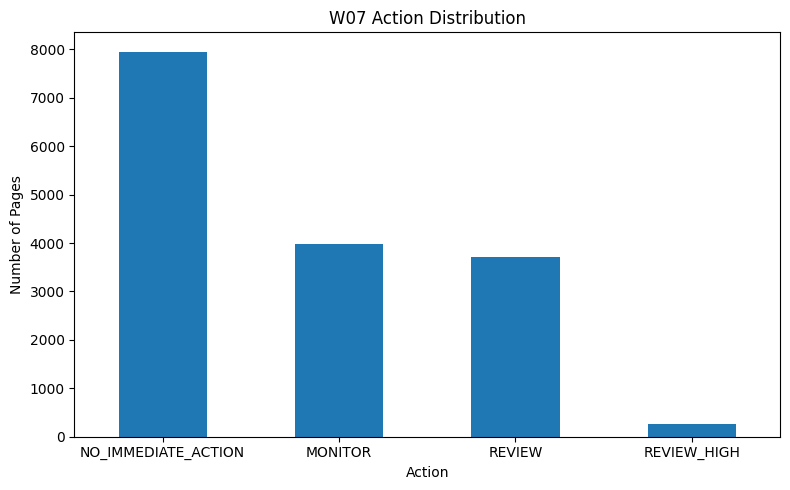

Saved: work/figures/w07_action_distribution.png


In [102]:
import matplotlib.pyplot as plt

action_counts = ranked_queue["action"].value_counts()

plt.figure(figsize=(8, 5))
action_counts.plot(kind="bar")

plt.title("W07 Action Distribution")
plt.xlabel("Action")
plt.ylabel("Number of Pages")
plt.xticks(rotation=0)
plt.tight_layout()

figure_path = FIGURE_DIR / "w07_action_distribution.png"
plt.savefig(figure_path, dpi=150)
plt.show()

print("Saved:", figure_path)

In [103]:
print("Figure exists:", figure_path.exists())
print("File size (KB):", round(figure_path.stat().st_size / 1024, 2))

Figure exists: True
File size (KB): 37.55


In [104]:
# Final export self-check

required_outputs = [
    OUTPUT_DIR / "w07_ranked_action_queue.csv",
    OUTPUT_DIR / "w07_playbook_metrics.json",
    FIGURE_DIR / "w07_action_distribution.png"
]

for path in required_outputs:
    print(path, "->", "OK" if path.exists() else "MISSING")

work/outputs/w07_ranked_action_queue.csv -> OK
work/outputs/w07_playbook_metrics.json -> OK
work/figures/w07_action_distribution.png -> OK


The final W07 playbook outputs were exported for use in the paper and review workflow.

### Ranked Action Queue

The ranked queue contains 15,908 content pages and includes the model priority score, action label, reason code, and supporting performance signals. Pages are sorted from highest to lowest model priority score.

Saved to:

`work/outputs/w07_ranked_action_queue.csv`

### Playbook Metrics

Key queue-level metrics and distributions were saved as a JSON file for reproducibility and reporting.

Saved to:

`work/outputs/w07_playbook_metrics.json`

### Action Distribution Figure

The distribution of recommended actions was visualized to show how pages are divided across the four priority levels:

- `REVIEW_HIGH`
- `REVIEW`
- `MONITOR`
- `NO_IMMEDIATE_ACTION`

Saved to:

`work/figures/w07_action_distribution.png`

All three output files were successfully verified after export.

## Self-check

Before you submit, confirm each line honestly:

- [x] Every section above is filled — markdown thinking AND the code that backs it
- [x] The notebook runs top to bottom with no errors (Runtime → Run all)
- [x] No client names, URLs, or private queries anywhere
- [x] My claims use careful words: observed, measured, directional, decision-support
- [x] Committed to my repo under `work/notebooks/` — then submit your repo URL on the card. Done.